In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import coint
from statsmodels.regression.linear_model import OLS
from statsmodels.tools.tools import add_constant
from hurst import compute_Hc
from statsmodels.tsa.stattools import adfuller
import seaborn as sns
import matplotlib.dates as mdates

In [22]:
def parse_pair(pair):
    """Parse pair string S1-S2 into tickers S1 and S2."""
    dp = pair.find('-')
    s1 = pair[:dp]
    s2 = pair[dp+1:]
    return s1, s2

def calculate_halflife(spread):
    """Calculate half-life of mean reversion of the spread."""
    ylag = spread.shift()
    deltay = spread - ylag
    ylag.dropna(inplace=True)
    deltay.dropna(inplace=True)
    res = OLS(deltay, add_constant(ylag)).fit()
    halflife = -np.log(2) / res.params[0]
    return halflife

def calculate_metrics(pairs, cumret, pairs_df):
    """Calculate metrics for pairs using data in cumret, including additional statistics."""
    # Define the multi-level columns for grouping related metrics
    cols = pd.MultiIndex.from_tuples([
        ('Hedge ratio', ''),
        ('CADF Test', 'Test Statistic'),
        ('CADF Test', 'p-value'),
        ('CADF Test', 'Critical Value 1%'),
        ('CADF Test', 'Critical Value 5%'),
        ('CADF Test', 'Critical Value 10%'),
        ('ADF Test', 'Test Statistic'),
        ('ADF Test', 'p-value'),
        ('ADF Test', 'Number of Lags Used'),
        ('ADF Test', 'Number of Observations Used'),
        ('ADF Test', 'Critical Value 1%'),
        ('ADF Test', 'Critical Value 5%'),
        ('ADF Test', 'Critical Value 10%'),
        ('Spread SD', ''),
        ('Pearson r', ''),
        ('Num zero-crossings', ''),
        ('Hurst Exponent', ''),
        ('Half-life of mean reversion', ''),
        ('% days within historical 2-SD band', '')
    ])
    results = pd.DataFrame(index=pairs, columns=cols)
    
    for pair in pairs:
        s1, s2 = parse_pair(pair)
        hedge_ratio = pairs_df.loc[pair]['Hedge ratio']
        spread = cumret[s1] - hedge_ratio * cumret[s2]
        results.loc[pair, ('Hedge ratio', '')] = hedge_ratio
        
        # Cointegration test with full output under CADF Test category
        coint_result = coint(cumret[s1], cumret[s2])
        results.loc[pair, ('CADF Test', 'Test Statistic')] = coint_result[0]
        results.loc[pair, ('CADF Test', 'p-value')] = coint_result[1]
        results.loc[pair, ('CADF Test', 'Critical Value 1%')] = coint_result[2][0]
        results.loc[pair, ('CADF Test', 'Critical Value 5%')] = coint_result[2][1]
        results.loc[pair, ('CADF Test', 'Critical Value 10%')] = coint_result[2][2]
        
        # ADF test on spread with full output under ADF Test category
        adf_result = adfuller(spread)
        results.loc[pair, ('ADF Test', 'Test Statistic')] = adf_result[0]
        results.loc[pair, ('ADF Test', 'p-value')] = adf_result[1]
        results.loc[pair, ('ADF Test', 'Number of Lags Used')] = adf_result[2]
        results.loc[pair, ('ADF Test', 'Number of Observations Used')] = adf_result[3]
        results.loc[pair, ('ADF Test', 'Critical Value 1%')] = adf_result[4]['1%']
        results.loc[pair, ('ADF Test', 'Critical Value 5%')] = adf_result[4]['5%']
        results.loc[pair, ('ADF Test', 'Critical Value 10%')] = adf_result[4]['10%']
        
        # Other metrics remain as single-level columns
        hist_mu = pairs_df.loc[pair]['Spread mean']
        hist_sd = pairs_df.loc[pair]['Spread SD']
        results.loc[pair, ('Spread SD', '')] = hist_sd
        results.loc[pair, ('Pearson r', '')] = np.corrcoef(cumret[s1], cumret[s2])[0][1]
        spread_nm = spread - hist_mu
        results.loc[pair, ('Num zero-crossings', '')] = ((spread_nm[1:].values * spread_nm[:-1].values) < 0).sum()
        results.loc[pair, ('Hurst Exponent', '')] = compute_Hc(spread)[0]
        results.loc[pair, ('Half-life of mean reversion', '')] = calculate_halflife(spread)
        results.loc[pair, ('% days within historical 2-SD band', '')] = (abs(spread - hist_mu) < 2 * hist_sd).sum() / len(spread) * 100
    return results

def plot_spread(pair, cumret, pairs_df):
    """Spread visualization."""
    s1, s2 = parse_pair(pair)
    hedge_ratio = pairs_df.loc[pair]['Hedge ratio']
    spread = cumret[s1] - hedge_ratio * cumret[s2]
    spread_mean = pairs_df.loc[pair]['Spread mean']
    spread_sd = pairs_df.loc[pair]['Spread SD']
    
    fig, ax = plt.subplots(figsize=(14, 7))
    ax.plot(spread, color='#1f77b4', linewidth=1.5, label='Normalized Spread')
    ax.axhline(spread_mean, color='#2ca02c', linestyle='--', linewidth=1.5, label='Historical Mean')
    ax.fill_between(spread.index, spread_mean - 2*spread_sd, spread_mean + 2*spread_sd,
                    color='#ff7f0e', alpha=0.15, label='±2σ Historical Band')
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
    plt.xticks(rotation=60)
    last_val = spread[-1]
    ax.annotate(f'Current Value: {last_val:.3f}',
                xy=(spread.index[-1], last_val),
                xytext=(10, 10), textcoords='offset points',
                arrowprops=dict(arrowstyle="->", color='black'))
    ax.set_title(f'{pair} Spread Analysis\n(March 31, 2020 - April 17, 2025)', fontsize=14, pad=20)
    ax.set_xlabel('Date', fontsize=12)
    ax.set_ylabel('Normalized Spread Value', fontsize=12)
    ax.legend(loc='upper left', frameon=True)
    plt.tight_layout()
    plt.show()

def plot_metrics(metrics):
    """Generate an enhanced table for Pair Analysis Metrics with grouped sections."""
    fig, ax = plt.subplots(figsize=(8, 10))
    ax.axis('off')

    # Prepare table data with grouped structure
    cell_text = []
    cell_colours = []
    # Define the order and grouping of metrics
    metric_groups = [
        ('Hedge ratio', [('Hedge ratio', '')]),
        ('CADF Test', [
            ('CADF Test', 'Test Statistic'),
            ('CADF Test', 'p-value'),
            ('CADF Test', 'Critical Value 1%'),
            ('CADF Test', 'Critical Value 5%'),
            ('CADF Test', 'Critical Value 10%')
        ]),
        ('ADF Test', [
            ('ADF Test', 'Test Statistic'),
            ('ADF Test', 'p-value'),
            ('ADF Test', 'Number of Lags Used'),
            ('ADF Test', 'Number of Observations Used'),
            ('ADF Test', 'Critical Value 1%'),
            ('ADF Test', 'Critical Value 5%'),
            ('ADF Test', 'Critical Value 10%')
        ]),
        ('Spread SD', [('Spread SD', '')]),
        ('Pearson r', [('Pearson r', '')]),
        ('Num zero-crossings', [('Num zero-crossings', '')]),
        ('Hurst Exponent', [('Hurst Exponent', '')]),
        ('Half-life of mean reversion', [('Half-life of mean reversion', '')]),
        ('% days within historical 2-SD band', [('% days within historical 2-SD band', '')])
    ]

    for group_name, sub_metrics in metric_groups:
        # Add group header row
        cell_text.append([group_name, ''])
        cell_colours.append(['#d3d3d3', '#d3d3d3'])  # Gray background for headers
        # Add sub-metrics
        for metric in sub_metrics:
            val = metrics.iloc[0][metric]
            # Format the metric name (remove group prefix for sub-metrics)
            metric_name = metric[1] if metric[1] else metric[0]
            # Format the value
            if 'p-value' in metric_name:
                formatted_val = f"{val:.2e}"
            elif 'Test Statistic' in metric_name or 'Critical Value' in metric_name:
                formatted_val = f"{val:.3f}"
            elif 'Number of Lags Used' in metric_name or 'Number of Observations Used' in metric_name or metric_name == 'Num zero-crossings':
                formatted_val = f"{int(val)}"
            elif '%' in metric_name:
                formatted_val = f"{val:.1f}%"
            elif metric_name == 'Half-life of mean reversion':
                formatted_val = f"{val:.1f}"
            elif metric_name in ['Hurst Exponent', 'Hedge ratio']:
                formatted_val = f"{val:.3f}"
            else:
                formatted_val = f"{val:.3f}"
            cell_text.append([f"  {metric_name}", formatted_val])  # Indent sub-metrics
            cell_colours.append(['#f8f9fa', '#ffffff'])  # Standard row colors

    # Create the table
    table = ax.table(cellText=cell_text, colLabels=['Metric', 'Value'], loc='center',
                     cellLoc='left', colColours=['#40466e', '#40466e'], cellColours=cell_colours)
    
    # Style the table
    table.auto_set_font_size(False)
    table.set_fontsize(10)
    table.scale(1.2, 1.2)
    
    # Adjust cell properties for better alignment
    for (row, col), cell in table.get_celld().items():
        if col == 0 and cell_text[row-1][1] == '':  # Group header rows
            cell.set_text_props(weight='bold')
            cell.set_height(0.05)
    
    plt.title('Pair Analysis Metrics', fontsize=15, pad=20)
    plt.tight_layout()
    plt.show()

C:\Users\19927\AppData\Local\Temp\ipykernel_30776\4269033243.py:3: FutureWarning: The argument 'date_parser' is deprecated and will be removed in a future version. Please use 'date_format' instead, or read your data in as 'object' dtype and then call 'to_datetime'.
  prices = pd.read_excel(


Metrics for BYD-TESLA pair:
          Hedge ratio      CADF Test                              \
                      Test Statistic   p-value Critical Value 1%   
BYD-TESLA    0.896557       -3.27333  0.058496         -3.902392   

                                                     ADF Test            \
          Critical Value 5% Critical Value 10% Test Statistic   p-value   
BYD-TESLA         -3.339447          -3.046752      -3.270019  0.016273   

                                                                             \
          Number of Lags Used Number of Observations Used Critical Value 1%   
BYD-TESLA                  10                        1833         -3.433923   

                                               Spread SD Pearson r  \
          Critical Value 5% Critical Value 10%                       
BYD-TESLA         -2.863118           -2.56761  0.227197  0.866065   

          Num zero-crossings Hurst Exponent Half-life of mean reversion  \
                 

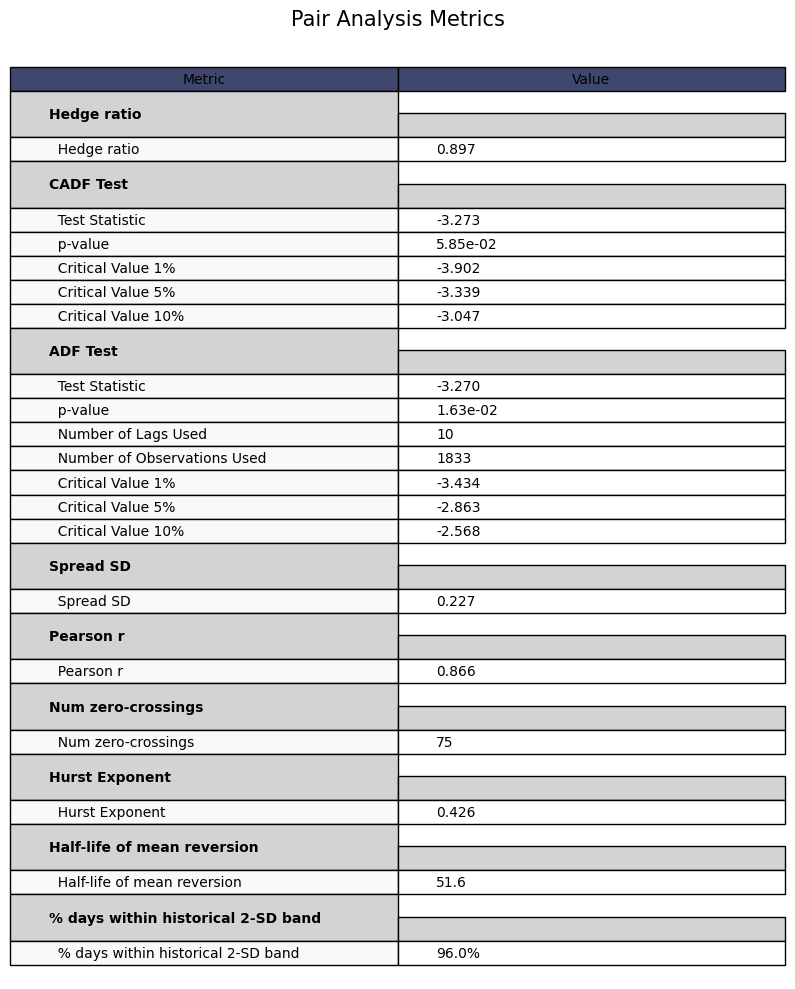


Spread Visualization with Statistical Bands


C:\Users\19927\AppData\Local\Temp\ipykernel_30776\1615227008.py:96: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  last_val = spread[-1]


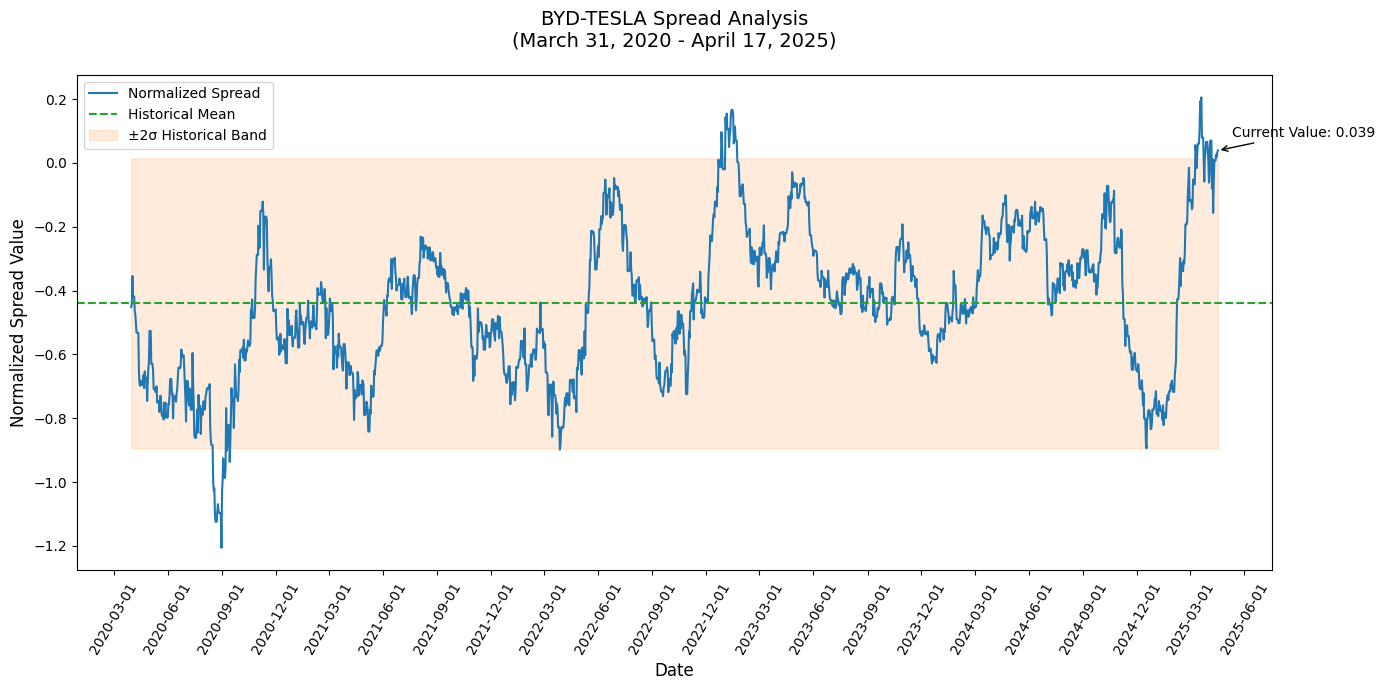

In [23]:
# Read the data
file_path = r'D:\MG\！CUHKSZ\~！大二 下\UBS瑞银 商赛\data\BYD&Tesla.xlsx'
prices = pd.read_excel(
    file_path,
    header=0,
    skiprows=[0],
    index_col='日期',
    parse_dates=['日期'],
    date_parser=lambda x: pd.to_datetime(x, format='%Y-%m-%d')
)
prices = prices[['比亚迪股份', '特斯拉(TESLA)']]
prices.columns = ['BYD', 'TESLA']
prices = prices[(prices['BYD'] > 0) & (prices['TESLA'] > 0)]

# Compute log prices
log_prices = np.log(prices)
log_prices = log_prices.replace([np.inf, -np.inf], np.nan)
log_prices = log_prices.dropna()

# Define the pair
pair = 'BYD-TESLA'
s1, s2 = parse_pair(pair)

# Compute hedge ratio
res = OLS(log_prices[s1], add_constant(log_prices[s2])).fit()
hedge_ratio = res.params[s2]

# Compute spread
spread = log_prices[s1] - hedge_ratio * log_prices[s2]

# Compute spread statistics
spread_mean = spread.mean()
spread_sd = spread.std()

# Create pairs_df
pairs_df = pd.DataFrame(index=[pair], columns=['Hedge ratio', 'Spread mean', 'Spread SD'])
pairs_df.loc[pair] = [hedge_ratio, spread_mean, spread_sd]

# Compute metrics
metrics = calculate_metrics([pair], log_prices, pairs_df)

# Display results
print("Metrics for BYD-TESLA pair:")
print(metrics)

# Generate enhanced metrics visualization
print("\n\033[1mPair Analysis Metrics\033[0m")
plot_metrics(metrics)

# Generate improved spread visualization
print("\n\033[1mSpread Visualization with Statistical Bands\033[0m")
plot_spread(pair, log_prices, pairs_df)